In [1]:
import sys
import os
import io
import pandas as pd
import numpy as np
from typing import Optional, Union
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath(".."))
from churn.datos import cargar_datos, tasa_por_grupo
from churn.eda import tasa_por_decil, graficar_tasa, margen_ic

In [2]:
margen_ic(0.5, 100)

0.098

In [3]:
df = cargar_datos("../data/dataset.csv")

In [4]:
promedio_global = df["churn"].mean()
promedio_global

np.float64(0.49562)

In [5]:
tasa_por_decil(df, 'months', 10)

,n_clientes,tasa_churn,margen_ic
months,,,
"(5.999, 8.0]",10002,0.330634,0.009220
"(8.0, 11.0]",16408,0.495917,0.007650
"(11.0, 12.0]",6033,0.618598,0.012257
"(12.0, 14.0]",10203,0.543664,0.009665
"(14.0, 16.0]",7435,0.517149,0.011359
"(16.0, 19.0]",10420,0.505278,0.009600
"(19.0, 23.0]",12481,0.508052,0.008771
"(23.0, 26.0]",7329,0.495566,0.011447
"(26.0, 33.0]",10933,0.510839,0.009370


In [6]:
segmento_meses = pd.cut(df["months"], bins=[0, 11, 24, df["months"].max()])
tasa_por_mes = tasa_por_grupo(df, segmento_meses, False)
tasa_por_mes

,n_clientes,tasa_churn
months,,
"(0, 11]",26410,0.433321
"(11, 24]",48901,0.530235
"(24, 61]",24689,0.493702


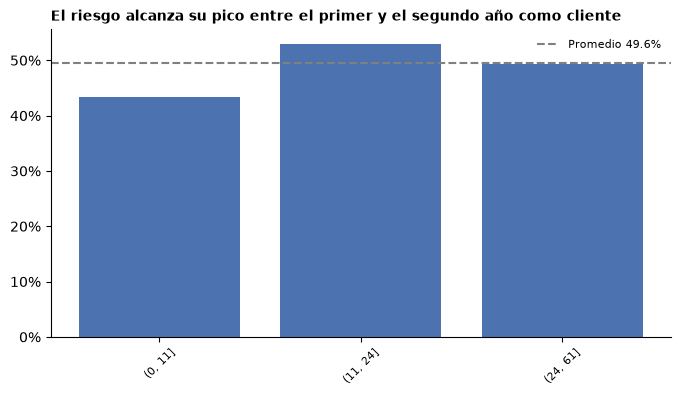

In [7]:

fig = graficar_tasa(
    tasa_por_mes,
    "El riesgo alcanza su pico entre el primer y el segundo año como cliente",
    promedio_global
)

In [8]:
numeric_cols = df.select_dtypes(include='number').columns.drop(['churn','Customer_ID'])

dif_tasas = pd.Series(
    {
        col: (t := tasa_por_decil(df, col, dropna=True)['tasa_churn']).max() - t.min()
        for col in numeric_cols
    },
    name="dif_tasa_churn"
).sort_values(ascending=False)

print(dif_tasas[:6])


months         0.287964
eqpdays        0.236783
hnd_price      0.214425
mou_Mean       0.146531
totmrc_Mean    0.131568
avg3mou        0.128536
Name: dif_tasa_churn, dtype: float64


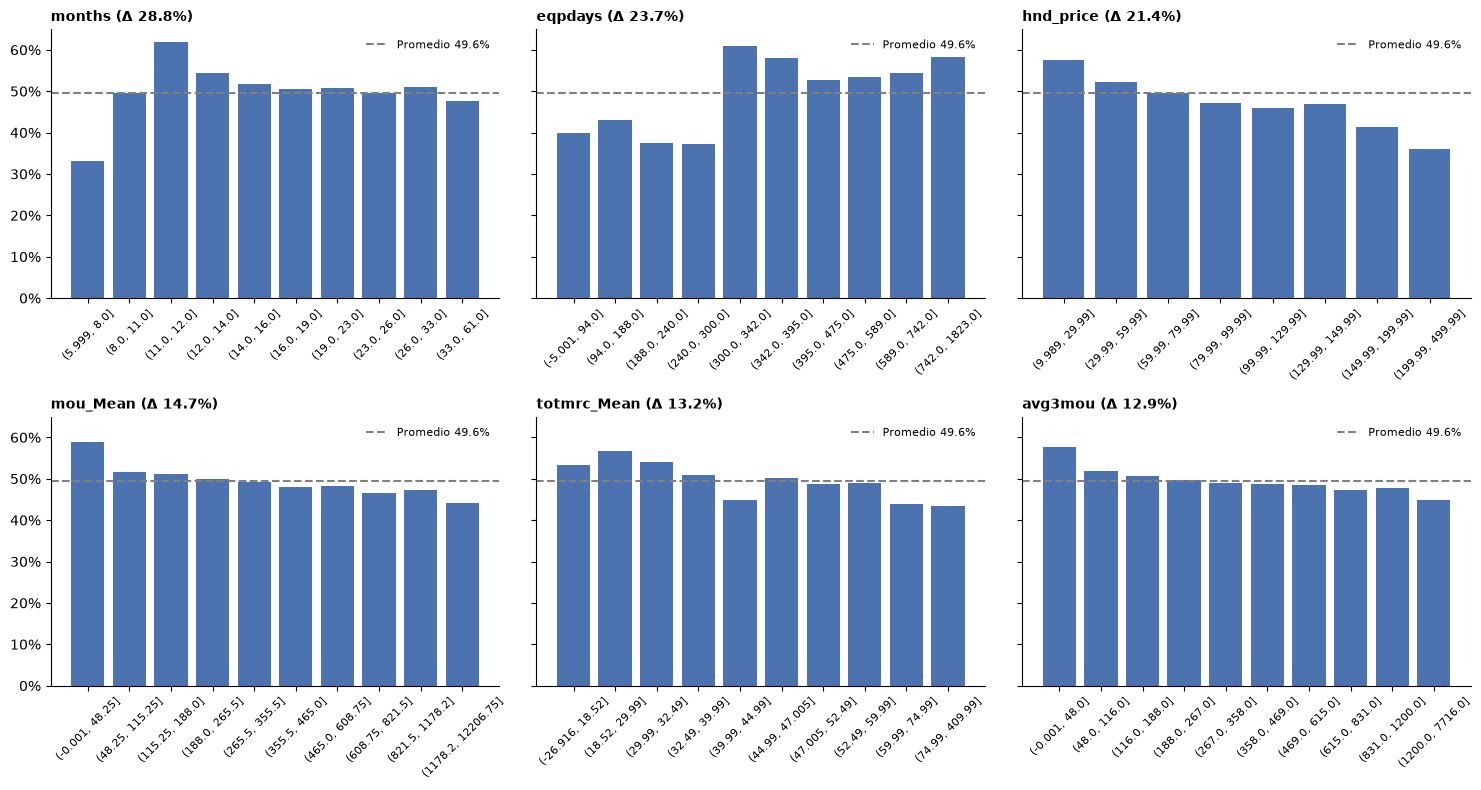

In [9]:
top_6_cols = dif_tasas.head(6).index

fig, axes = plt.subplots(2, 3, figsize=(15,8), sharey=True)

for col, ax in zip(top_6_cols, axes.flatten()):
    tabla_decil = tasa_por_decil(df, col, dropna=True)
    graficar_tasa(
        tabla=tabla_decil,
        titulo=f"{col} (Δ {dif_tasas[col]:.1%})",
        promedio=promedio_global,
        ax=ax
    )

plt.tight_layout()
plt.show()


### months: Total number of months in service
La tasa se mantiene abajo los primeros meses (5.999-11) luego comienza a subir alcanzando su pico en los meses 11-12 y después empieza a bajar poco a poco y se mantiene con diferencias mínimas.

### eqpdays: Number of days (age) of current mobile phone
La tasa se mantiene baja durante los días -0.5001 a 300 (aquí hay un error porque no tienen sentido valores negativos). Alcanza su pico en los días 300-342 y se mantiene por encima del promedio de ahí en adelante con diferencias mínimas entre deciles.
Entre el cuarto y el quinto decil hay un salto brusco, esto ocurre alrededor del día 300 (unos 10 meses).
Algo interesante es que months y eqpdays tienen su punto crítico cerca del año: months tiene el pico en 11-12 meses como cliente y eqpdays su salto está en ~10 meses de antigüedad del teléfono. Una hipótesis que conecta a ambas: en muchas telcos el teléfono viene con el contrato y se paga en mensualidades. Caundo se termina de pagar y el contrato vence, el cliente queda libre para irse, y además su teléfono ya está envejeciendo, así que busca uno nuevo, con la misma empresa o con la competencia. Eso sugiere una acción concreta: ofrecer la renovación del equipo antes de los ~300 días.

### hnd_price: Current handset price
La tasa de churn tiene su pico al principio (menor precio) y va disminuyendo conforme aumenta el precio teniendo su mínimo en los deciles más altos (mayores precios).

### mou_Mean: Mean number of monthly minutes of use
Como el hnd_price, la tasa baja conforme los deciles aumentan, en este caso, conforme el promedio de minutos de uso aumenta.

### totmrc_Mean: Mean total monthly recurring charge
Aquí la tasa va variando y la tendencia no es tan marcada pero aún así se nota que va bajando conforme el promedio del cargo mensual recurrente aumenta.

### avg3mou: Average monthly minutes of use over the previous three months
Aquí se ve un comportamiento que sigue la tendencia de mou_Mean, conforme aumenta el promedio de minutos, disminuye la tasa de churn.

In [10]:
# custcare_Mean: Mean number of customer care calls
tabla_formateada = tasa_por_decil(df, 'custcare_Mean',dropna = True)
tabla_formateada["tasa_churn"] = tabla_formateada["tasa_churn"].map(lambda x: f"{x:.1%}")
tabla_formateada

,n_clientes,tasa_churn,margen_ic
custcare_Mean,,,
"(-0.001, 0.333]",62905,51.5%,0.003906
"(0.333, 1.0]",8887,49.1%,0.010394
"(1.0, 2.333]",9178,46.6%,0.010206
"(2.333, 5.333]",9472,45.3%,0.010024
"(5.333, 675.333]",9558,44.1%,0.009954


In [11]:
uso_terciles = pd.qcut(
    df["mou_Mean"],
    3,
    labels=["Bajo uso", "Uso medio", "Alto uso"],
    duplicates="drop"
)

llamo_soporte = df["custcare_Mean"] > 0

resumen = (
    df.groupby([uso_terciles.rename("nivel_uso"), llamo_soporte.rename("llamo_soporte")], observed=True)
    .agg(
        n_clientes=('churn', 'count'),
        tasa_churn=('churn', 'mean')
    )
    .reset_index()
)

tabla_comparativa = resumen.pivot(
    index="nivel_uso", 
    columns="llamo_soporte", 
    values=["n_clientes","tasa_churn"]
).rename(columns={False: "No llamó soporte", True: "Sí llamó soporte"})

tabla_formateada = tabla_comparativa.copy()
tabla_formateada["tasa_churn"] = tabla_formateada["tasa_churn"].map(lambda x: f"{x:.1%}")

display(tabla_formateada)

n_clientes                        tasa_churn  \
llamo_soporte No llamó soporte Sí llamó soporte No llamó soporte   
nivel_uso                                                          
Bajo uso               26468.0           6757.0            53.7%   
Uso medio              18625.0          14594.0            49.8%   
Alto uso               10312.0          22887.0            49.7%   

                                
llamo_soporte Sí llamó soporte  
nivel_uso                       
Bajo uso                 52.4%  
Uso medio                47.5%  
Alto uso                 44.7%

La relación entre el nivel de uso y la tasa de churn se mantiene aún si hablaron o no a soporte. Se ve que en ambos grupos (Si llamó soporte, no llamó soporte), la tasa de churn disminuye cuando hay un mayor uso.
La relación original entre uso y tasa de churn explica muy bien que los clientes que más llaman se van menos incluso para los que más llaman a soporte.
Con esto, la única recomendación que podría hacer es mantener la línea de soporte porque se ve que ayuda a la retención de clientes pero también conocer más datos de esas llamadas ayudaría a conocer exactamente qué pasa y qué es lo que hace que los clientes se queden cuando más llaman a soporte.

In [12]:
# Matriz de correlación
corr_matrix = (
    df[numeric_cols]
    .corr(method="spearman")
)

In [13]:
# Máscara para conservar solo el triángulo superior (excluyendo diagonal k=1)
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)

# Filtrar, aplanar y ordenar por magnitud
pares_alta_corr = (
    corr_matrix.where(mask)
    .stack()
    .rename("spearman_r")
    .loc[lambda r: r.abs() > 0.9]
    .reset_index()
    .rename(columns={'level_0': 'var_1', 'level_1': 'var_2'})
    .assign(abs_r=lambda d: d['spearman_r'].abs())
    .sort_values(by='abs_r', ascending=False)
    .drop(columns='abs_r')
).sort_values(by='spearman_r', ascending=False)

display(pares_alta_corr)

,var_1,var_2,spearman_r
45,totcalls,adjqty,0.999470
46,totmou,adjmou,0.999451
14,plcd_vce_Mean,attempt_Mean,0.999364
24,comp_vce_Mean,complete_Mean,0.999166
37,peak_dat_Mean,mou_pead_Mean,0.999160
25,comp_dat_Mean,mou_cdat_Mean,0.998889
41,opk_dat_Mean,mou_opkd_Mean,0.998804
28,ccrndmou_Mean,cc_mou_Mean,0.998112
5,ovrmou_Mean,ovrrev_Mean,0.997827
48,totrev,adjrev,0.995622


In [14]:
pares_alta_corr.shape

(60, 3)

In [15]:
familias_variables = {
    "Ingresos y Facturación": [
        "rev_Mean", "avg3rev", "avg6rev", "avgrev", "totrev", "adjrev"
    ],
    "Excedentes (Overage)": [
        "ovrmou_Mean", "ovrrev_Mean", "vceovr_Mean"
    ],
    "Volumen de Minutos (Voz y General)": [
        "mou_Mean", "avg3mou", "avg6mou", "avgmou", "totmou", "adjmou",
        "mou_cvce_Mean", "mou_peav_Mean", "mou_opkv_Mean", "mou_rvce_Mean",
        "mouowylisv_Mean", "mouiwylisv_Mean", "inonemin_Mean"
    ],
    "Conteo y Estado de Llamadas": [
        "totcalls", "adjqty", "avgqty", "avg3qty", "avg6qty",
        "attempt_Mean", "complete_Mean", "plcd_vce_Mean", "comp_vce_Mean",
        "peak_vce_Mean", "opk_vce_Mean", "recv_vce_Mean", "unan_vce_Mean",
        "owylis_vce_Mean", "iwylis_vce_Mean"
    ],
    "Uso y Sesiones de Datos": [
        "plcd_dat_Mean", "comp_dat_Mean", "mou_cdat_Mean",
        "peak_dat_Mean", "mou_pead_Mean", "opk_dat_Mean", "mou_opkd_Mean"
    ],
    "Soporte y Atención al Cliente": [
        "custcare_Mean", "cc_mou_Mean", "ccrndmou_Mean"
    ],
    "Dispositivos y Equipamiento": [
        "phones", "models"
    ]
}

In [ ]:
# Invertir el diccionario para mapeo: {columna: familia}
var_a_familia = {
    var: familia 
    for familia, vars_list in familias_variables.items() 
    for var in vars_list
}

# Asignar familias a tabla de correlaciones
pares_alta_corr["familia_1"] = pares_alta_corr["var_1"].map(var_a_familia).fillna("Otros")
pares_alta_corr["familia_2"] = pares_alta_corr["var_2"].map(var_a_familia).fillna("Otros")
pares_alta_corr["misma_familia"] = pares_alta_corr["familia_1"] == pares_alta_corr["familia_2"]

display(pares_alta_corr)

,var_1,var_2,spearman_r,familia_1,familia_2,misma_familia
45,totcalls,adjqty,0.999470,Conteo y Estado de Llamadas,Conteo y Estado de Llamadas,True
46,totmou,adjmou,0.999451,Volumen de Minutos (Voz y General),Volumen de Minutos (Voz y General),True
14,plcd_vce_Mean,attempt_Mean,0.999364,Conteo y Estado de Llamadas,Conteo y Estado de Llamadas,True
24,comp_vce_Mean,complete_Mean,0.999166,Conteo y Estado de Llamadas,Conteo y Estado de Llamadas,True
37,peak_dat_Mean,mou_pead_Mean,0.999160,Uso y Sesiones de Datos,Uso y Sesiones de Datos,True
25,comp_dat_Mean,mou_cdat_Mean,0.998889,Uso y Sesiones de Datos,Uso y Sesiones de Datos,True
41,opk_dat_Mean,mou_opkd_Mean,0.998804,Uso y Sesiones de Datos,Uso y Sesiones de Datos,True
28,ccrndmou_Mean,cc_mou_Mean,0.998112,Soporte y Atención al Cliente,Soporte y Atención al Cliente,True
5,ovrmou_Mean,ovrrev_Mean,0.997827,Excedentes (Overage),Excedentes (Overage),True
48,totrev,adjrev,0.995622,Ingresos y Facturación,Ingresos y Facturación,True


In [18]:
import pandas as pd

# 1. Crear un DataFrame base con todas las variables y sus familias
df_variables = pd.DataFrame(
    list(var_a_familia.items()), 
    columns=['variable', 'familia']
).set_index('variable')

# 2. Calcular la cantidad de nulos de cada variable en el DataFrame original
nulos_series = df[df_variables.index].isna().sum().rename('cantidad_nulos')

# 3. Unir la señal y los nulos al DataFrame base
df_evaluacion = (
    df_variables
    .join(dif_tasas.rename('senal'))
    .join(nulos_series)
    .reset_index()
)

# 4. Ordenar y filtrar
variables_a_conservar = (
    df_evaluacion
    # Ordenar por familia, luego mayor señal (False), luego menores nulos (True)
    .sort_values(
        by=['familia', 'senal', 'cantidad_nulos'], 
        ascending=[True, False, True],
        na_position='last'  # Si alguna no tiene señal, se va al fondo
    )
    # Quedarse solo con la primera fila de cada familia (la que cumple los criterios)
    .drop_duplicates(subset=['familia'], keep='first')
    .reset_index(drop=True)
)

display(variables_a_conservar)

,variable,familia,senal,cantidad_nulos
0,complete_Mean,Conteo y Estado de Llamadas,0.127284,0
1,models,Dispositivos y Equipamiento,0.058746,1
2,ovrmou_Mean,Excedentes (Overage),0.048113,357
3,adjrev,Ingresos y Facturación,0.119853,0
4,custcare_Mean,Soporte y Atención al Cliente,0.074373,0
5,plcd_dat_Mean,Uso y Sesiones de Datos,0.043223,0
6,mou_Mean,Volumen de Minutos (Voz y General),0.146531,357
